In [21]:
import gymnasium as gym

import numpy as np
import time
import matplotlib.pyplot as plt
import random 
import numpy as np
from collections import defaultdict
 
 

env=gym.make('CartPole-v1')#,render_mode='human')

(state,_)=env.reset()

In [22]:
def treatState(state):
    state[0]=np.digitize(state[0],pos_space)
    state[1]=np.digitize(state[1],vel_space)
    state[2]=np.digitize(state[2],ang_space)
    state[3]=np.digitize(state[3],ang_vel_space)
    return state

In [23]:
class Qlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,std):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.std=std
        
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def episodeRewards(self,episodes,goal):
        result=len(episodes)
        if result < goal-self.std:
            reward=1
        elif result > goal+self.std:
            reward=-1
        else:
            reward=goal - abs(goal-result)
        for i in range(len(episodes)-1,-1,-1):
            """if i < goal-10:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],1)
                continue
            if i > goal+10:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],-1)
                continue"""
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma

### learner rewards

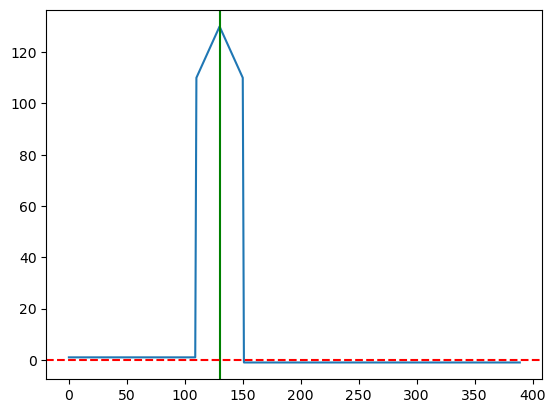

In [24]:
values=[]
goal=130
std=20
for i in range(goal*3):
    if i < goal-std:
        values.append(1)
        continue
    if i > goal+std:
        values.append(-1)
        continue
    values.append(goal-abs(goal-i))
plt.plot(values)
plt.axvline(x= goal,color ='g')
plt.axhline(y= 0,color ='r',linestyle = "dashed")
plt.savefig("SVG/GoalRewardSTD"+str(std)+"_reward.svg")

In [25]:
def KL(a,b):
       
        if len(a)<len(b):
            return 1
        return np.sum(a*np.log(a/b))

### Test

In [26]:
goal=130

In [27]:
episodeNumber=30000
timeSteps=10000
episodesResults=[]
episodesTestResults=[]
episodesTestResultsDeviation=[]
KLdivergenceResult=[]
goaldistr=np.random.normal(loc=130,scale=10,size=1000)
numberOfTest=50
qagent= Qlearning(0.3,0.99,0.1,2,std)
pos_space=np.linspace(-2.4,2.4,10)
vel_space=np.linspace(4,4,10)
ang_space=np.linspace(-0.2095,0.2095,10)
ang_vel_space=np.linspace(-4,4,10)

In [28]:
for episodeIndex in range(episodeNumber):
    
    state,_=env.reset()
    state=treatState(state)
    #print("episode: ",episodeIndex)
    episodeObservation=[]
    for timeIndex in range(timeSteps):
        action=qagent.getAction(tuple(state))
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state)
        episodeObservation.append([tuple(state),action,tuple(next_state)])
        #qagent.update(tuple(state),action,tuple(next_state),reward)
        state=next_state
        if (terminated):
            #print("Number of steps :",timeIndex)
            #if(episodeIndex %500 ==0):
                #episodesTestResults.append(timeIndex)
            episodesResults.append(timeIndex)
            break

    qagent.episodeRewards(episodeObservation,goal)

    if (episodeIndex %1000 ==0):
        KLdivergenceResult.append(KL(goaldistr, episodesResults[-1000:]))
    if(episodeIndex %500 ==0):
        qagent.epsilon=0
        testResultList=[]
        for episodeIndex in range(numberOfTest):
    
            state,_=env.reset()
            state=treatState(state)
            for timeIndex in range(timeSteps):
                action=qagent.getAction(tuple(state))
                next_state, reward, terminated, truncated, info =env.step(action)
                next_state=treatState(next_state)
                state=next_state
                if (terminated):
                    testResultList.append(timeIndex)
                    break

        episodesTestResults.append(sum(testResultList)/numberOfTest)
        episodesTestResultsDeviation.append(np.std(episodesTestResults))
        qagent.epsilon=0.1
    

qagent.epsilon=0
last1000testList=[]
for episodeIndex in range(1000):
    
    state,_=env.reset()
    state=treatState(state)
    for timeIndex in range(timeSteps):
        action=qagent.getAction(tuple(state))
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state)
        state=next_state
        if (terminated):
            last1000testList.append(timeIndex)
            break


qagent.epsilon=0.1
env.close() 

117.21326666666667


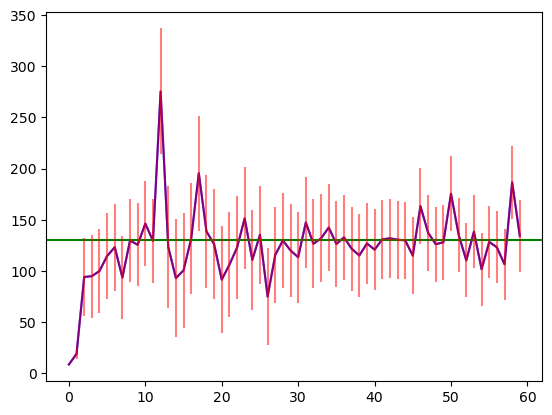

In [29]:
plt.plot(episodesTestResults,color ='b')
plt.axhline(y= goal,color ='g')
plt.errorbar(range(len(episodesTestResults)),episodesTestResults,yerr=episodesTestResultsDeviation,color ='r',alpha=0.5)
plt.savefig("SVG/GoalRewardSTD"+str(std)+"_1.svg")
print(sum(episodesResults)/len(episodesResults))

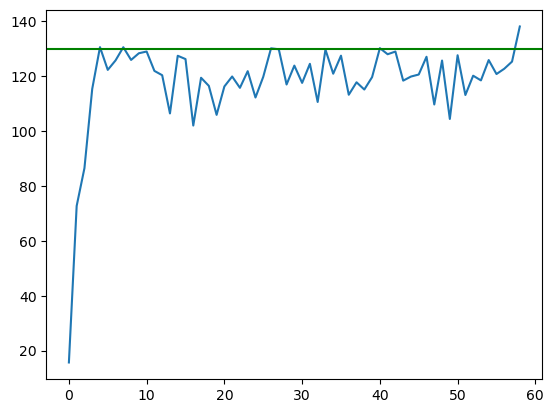

In [30]:
previous100AveragePlot=[]
for i in range(1,len(episodesTestResults)):
    previous100AveragePlot.append(sum(episodesResults[(i*500)-100:(i*500)])/100)

plt.plot(previous100AveragePlot)
plt.axhline(y= goal,color ='g')
plt.savefig("SVG/GoalRewardSTD"+str(std)+"_2.svg")

1015


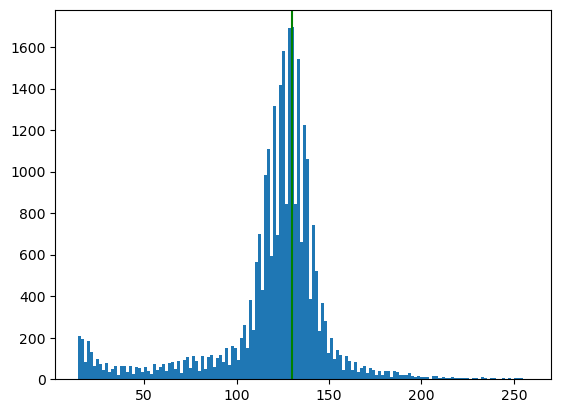

In [31]:
#histogram
episodesResultswithoutOutliers=[]
for i in episodesResults:
    if i >goal * 0.1 and i < goal*2:
        episodesResultswithoutOutliers.append(i)
plt.hist(episodesResultswithoutOutliers,bins=150)
plt.axvline(x= goal,color ='g')
plt.savefig("SVG/GoalRewardSTD"+str(std)+"_3.svg")
print(len(episodesResults)-len(episodesResultswithoutOutliers))

1015


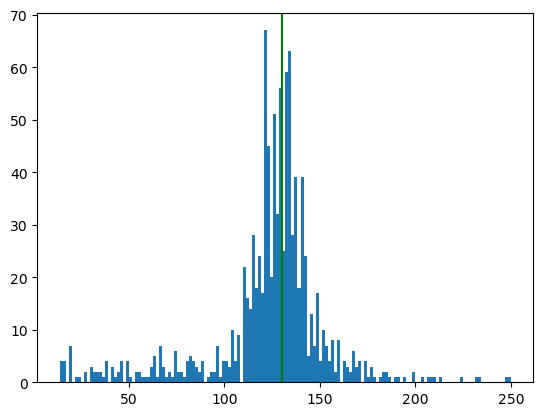

In [32]:
episodesResultswithoutOutliers=[]
for i in episodesResults:
    if i >goal * 0.1 and i < goal*2:
        episodesResultswithoutOutliers.append(i)
plt.hist(episodesResultswithoutOutliers[-1000:],bins=150)
plt.axvline(x= goal,color ='g')
plt.savefig("SVG/GoalRewardSTD"+str(std)+"_4.svg")
print(len(episodesResults)-len(episodesResultswithoutOutliers))


In [33]:
print(np.mean(episodesResultswithoutOutliers[-1000:]))
print(np.std(episodesResultswithoutOutliers[-1000:]))
print(np.mean(episodesResultswithoutOutliers))
print(np.std(episodesResultswithoutOutliers))

123.499
30.64059397270229
119.64757633258581
31.894681241067293


self std 20:<br />

121.903 <br />

32.8791<br />
5
119.027890641140 <br />
42
31.866642988476 624

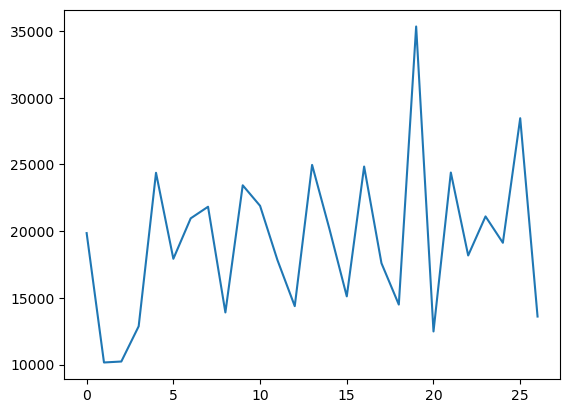

In [34]:
plt.plot(KLdivergenceResult[3:])

3829


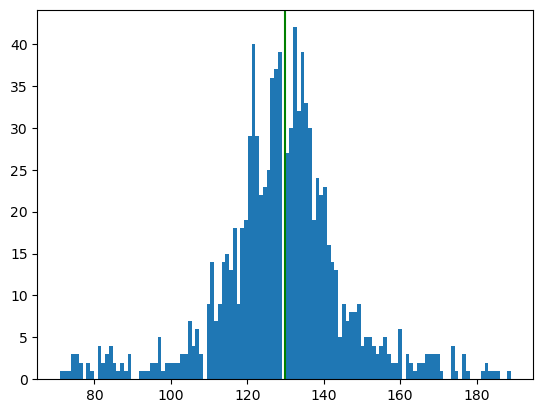

In [35]:
episodesResultswithoutOutliers=[]
for i in episodesResults:
    if i >goal -60 and i < goal+60:
        episodesResultswithoutOutliers.append(i)
plt.hist(episodesResultswithoutOutliers[-1000:],bins=120)
plt.axvline(x= goal,color ='g')
print(len(episodesResults)-len(episodesResultswithoutOutliers))


114.799
18.328300494044722


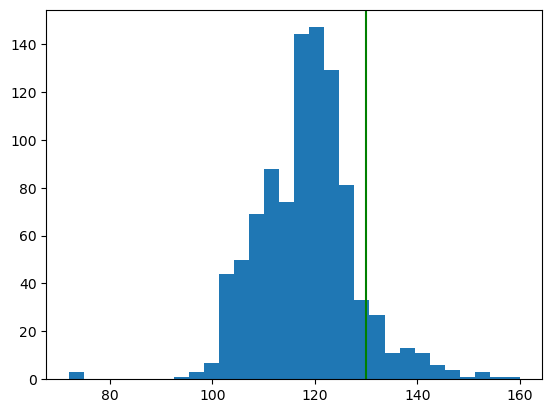

In [36]:

episodesResultswithoutOutliers=[]
for i in last1000testList:
    if i >goal -60 and i < goal+60:
        episodesResultswithoutOutliers.append(i)
plt.hist(episodesResultswithoutOutliers,bins=30)
plt.axvline(x= goal,color ='g')
plt.savefig("SVG/GoalRewardSTD"+str(std)+"_5.svg")
print(np.mean(last1000testList))
print(np.std(last1000testList))

In [37]:
print(np.mean(goaldistr))
print(np.std(goaldistr))

130.1393246597237
9.904491049280198


In [38]:
goal9LearnerEp=episodesResults
%store goal9LearnerEp
goal9learnerTestEp=episodesTestResults
%store goal9learnerTestEp

Stored 'goal9LearnerEp' (list)
Stored 'goal9learnerTestEp' (list)


In [39]:
def uniTest(agent,epsilon=0):
    qagent.epsilon=epsilon
    last1000testList=[]
    for episodeIndex in range(1000):
    
        state,_=env.reset()
        state=treatState(state)
        for timeIndex in range(timeSteps):
            action=qagent.getAction(tuple(state))
            next_state, reward, terminated, truncated, info =env.step(action)
            next_state=treatState(next_state)
            state=next_state
            if (terminated):
                last1000testList.append(timeIndex)
                break
    return np.mean(last1000testList),np.std(last1000testList)

0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9


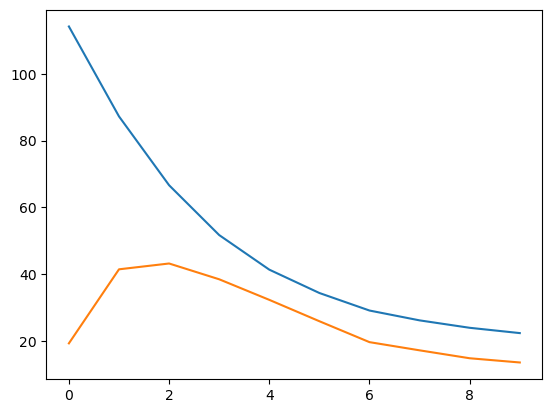

In [40]:
multimean=[]
multistd=[]
for epsilon in range(0,10):
    print(epsilon/10)
    tmpresult=uniTest(qagent,epsilon/10)
    multimean.append(tmpresult[0])
    multistd.append(tmpresult[1])
plt.plot(multimean)
plt.plot(multistd)